# Chapter 8: Convolutional Neural Networks

### Cifar2 Data from Ch 7.

In [13]:
import torch
from torchvision import datasets, transforms

# Getting cifar10 dataset
data_path = 'data/ch7'  # Path to cifar10 data from ch 7.  
cifar10 = datasets.CIFAR10(data_path, train=True, download=True, transform=transforms.ToTensor()) 
cifar10_val = datasets.CIFAR10(data_path, train=False, download=True, transform=transforms.ToTensor())
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Normalizing Data
imgs = torch.stack([img_t for img_t, _ in cifar10], dim = 3)

data_mean = imgs.view(3, -1).mean(dim=1).tolist()
data_std = imgs.view(3, -1).std(dim=1).tolist()

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize(mean=data_mean, std=data_std)])

cifar10 = datasets.CIFAR10(data_path, train=True, download=True, transform=transform) 
cifar10_val = datasets.CIFAR10(data_path, train=False, download=True, transform=transform)

# Building cifar2 dataset
label_map = {0:0, 2:1}  # Remaps label 2 (birds) in CIFAR dataset to be label 1 for our dataset
class_names = ['airplane', 'bird']
cifar2 = [(img, label_map[label]) for img, label in cifar10 if label in [0, 2]]
cifar2_val = [(img, label_map[label]) for img, label in cifar10_val if label in [0, 2]]

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified


## Creating a Convolutional Module

- Torch.nn provides the nn.Conv modules for convolutions in 1, 2 and 3D \
  --> 1D is used for time series, 2D for images and 3D for volumetric data and videos
- Argumnments for layer: nn.Conv(input features/channels, output features, kernal_size) \
  --> More channels in output image (output features) = higher the network capcity -- Each channels detects 1 distinct feature. \
  --> If only 1 value is passed to kernal size, assumes square/cube. If want multiple values can pass as tuple ex. (3, 3) -- Common for kernal size to be same in all dim.
- A convolutional layer contains multiple kernels in weight matrix.
  --> Conv. weight shape = kernal_size x in_featu. (as seperate kernal is needed to handel each channel) x out_featu. (as each kernals detects diffrent patterns)

In [14]:
import torch
import torch.nn as nn

# Creating Conv2d for image
conv = nn.Conv2d(3, 16, kernel_size=3) # Arbitraily using 16 out. features -- to detect 16 distinct patterns/features
conv

# Check Conv. layer weight and bias
conv, conv.weight.shape, conv.bias.shape # Bias shape = # output featu. Since 1 val is added per out featu.

(Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1)),
 torch.Size([16, 3, 3, 3]),
 torch.Size([16]))

Passing an image through conv. to get output image
- 2D conv. produces 2D img where pixels are a weighted sum of a group of pixels (neighbourhood) in the input img
- layer expects a B x C x H x W tensor for image input. (Like all nn modules)

In [15]:
import matplotlib.pyplot as plt

# Getting sample img from cifar2
img, _ = cifar2[0]
img = img.unsqueeze(0) # Adding batch dim at idx 0

output = conv(img) # Pass through conv -- Won't produce anything useful --> weights and bias are randomly initialised
img.shape, output.shape

(torch.Size([1, 3, 32, 32]), torch.Size([1, 16, 30, 30]))

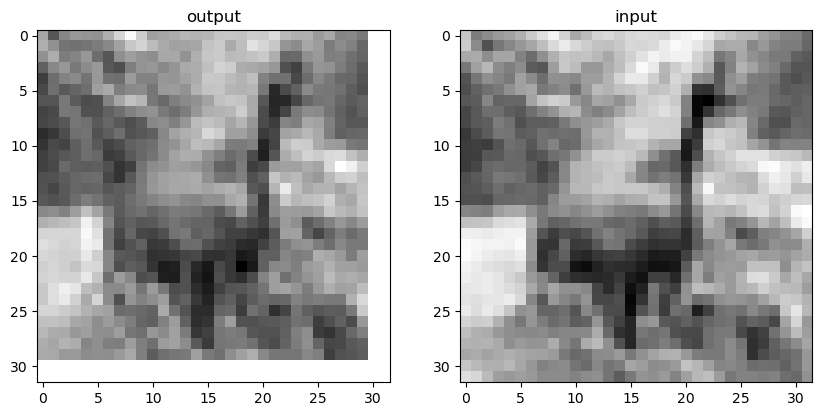

In [16]:
# Displaying output img
# %matplotlib inline
# plt.imshow(output[0, 0].detach(), cmap='gray')
# plt.show()

# Show both input and output
%matplotlib inline
plt.figure(figsize=(10, 4.8))
ax1 = plt.subplot(1, 2, 1)
plt.title('output')
plt.imshow(output[0, 0].detach(), cmap='gray')
plt.subplot(1, 2, 2, sharex=ax1, sharey=ax1) 
plt.imshow(img[0, 0], cmap='gray') 
plt.title('input') 
plt.show()

#### Adding Padding to img

- Since a convolution requires neighbours (of the kernal "radius") in all directions, from the center, to compute (the weighted sum and as a result) the output, at the edge of the images there will be no output. \
--> loosing (k-1 / 2) (for a k x k kenal) pixels on each side of the image
- Fix this by adding a padding (of ghost pixels) (of size k - 1 / 2) to the input image, by passing the padding size the the conv layer constuctor \
--> Padding would be diffrent of diff sizes for even kernal, so ***Stick to odd sized kernals***

In [17]:
conv = nn.Conv2d(3, 1, kernel_size=3, padding=1)
output = conv(img)
img.shape, output.shape

(torch.Size([1, 3, 32, 32]), torch.Size([1, 1, 32, 32]))

### Detecting Features with Convolutions

#### Hand setting conv weight to see effect


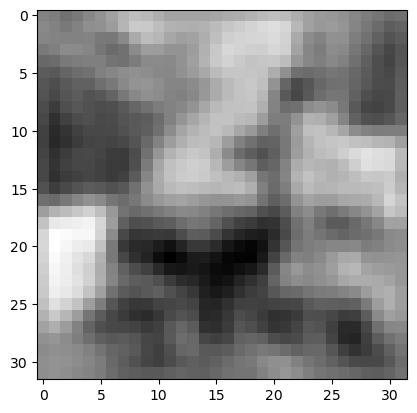

In [18]:
with torch.no_grad():
    conv.bias.zero_() # Zeroing bias

with torch.no_grad():
    conv.weight.fill_(1.0 / 9.0) # Making Each pixel in output get mean value of its 3 x 3 neighbours

# Applying convolution and viewing output image -- Produces blured image!
out = conv(img)
%matplotlib inline
plt.imshow(out[0, 0].detach(), cmap='gray')
plt.show()

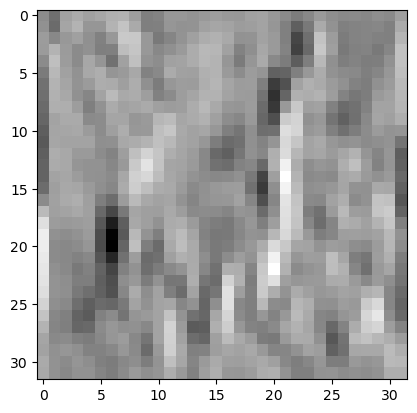

In [19]:
with torch.no_grad():
    conv.weight[:] = torch.tensor([[-1.0, 0.0, 1.0],
                                   [-1.0, 0.0, 1.0],
                                   [-1.0, 0.0, 1.0],
                                   ])
    conv.bias.zero_()

# Applying convolution and viewing output image -- Detects edges! --> Diffrence of pixels
out = conv(img)
%matplotlib inline
plt.imshow(out[0, 0].detach(), cmap='gray')
plt.show()

#### Downsampling Images

- The small kernal size won't capure the whole object we want, so we need a way to combine convolutions (distinct objects features) into the bigger picture (the whole object)
- The way to do this is to downsample (scale down the output) and stack sucessive convolutions
- The most common approach for downsampling is max poooling
  --> Take the maximum of a group of pixels and use that as the output. \
  (eg. To scale an img by half using max pooling, take the max value from a group 4 pixels and use that pixel as the 1 out.)
- Max Polling function (for 1, 2 and 3D data) is provided in torch.nn module

In [20]:
pool = nn.MaxPool2d(2) #MaxPool(input to pool (per dim))
output = pool(img)
img.shape, output.shape # For every 2 pixels, return the max, for both height and width 

(torch.Size([1, 3, 32, 32]), torch.Size([1, 3, 16, 16]))

#### Conbining Convolutions with Downsampling

1. Apply the first conv to the img. --> The first set of kernal will extract distinct (low-level) features (eg. edges textures)
2. Downsample the conv. output --> Get a smaller image with the important features
3. Apply another convolution layer --> This set of sernals extracts more complex features (such as objects) from the composition of the previous features detected by the first set of kernals.

- Each network layer looks at smaller input images that correspond to larger areas of the original image. The end result is a small output image (in this case 4x4) captures all the important features from the original (larger) image. \
--> **Receptive field of output pictures:** Area of the original image represented by (each pixel) in the final output.

- After applying all the convolution layers, pass final output to linear (Fully Connected) Network to classify the object. 

In [21]:
# Creating a convolutional neural network -- Using previous model as starting point
model = nn.Sequential(
                      # Conv. Layers --> "Filter"
                      nn.Conv2d(3, 16, kernel_size=3, padding=1),
                      nn.Tanh(),
                      nn.MaxPool2d(2),
                      nn.Conv2d(16, 8, kernel_size=3, padding=1),
                      nn.Tanh(),
                      nn.MaxPool2d(2),
                      #... <-- Somthing missing -- A way to flaten conv output to 1D vector
                      #  Linear Layers --> "Classifier"
                      nn.Linear(8 * 8 * 8, 32),  # Last conv layer outputs 8 channels, x 8 x 8 image output from last max pool layer
                      nn.Tanh(),
                      nn.Linear(32, 2))

# Inspecting Model Parameters
numel_list = [p.numel() for p in model.parameters()]
sum(numel_list), numel_list

out = model(img) # Will fail

(18090, [432, 16, 1152, 8, 16384, 32, 64, 2])

## Creating Custom Models

- Creating a subclass of nn.Module allows you need to build models more complex than applying one layer directly after another. -- This will help solve the issue above
- To subclass nn.module, need to define  a forward function to take inputs to module and get output.
- To include submodules (like nn.Linear or Conv), define them in your subclass construtructor (with self.submodule) (__ init __ ) **And** call super().__ init __() \
--> Submodules will hold their parameters as usual (for the lifetime of the module) 

In [1]:
class Net(nn.Module):
    def __init__(self):
        # Defining Net Submodules
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.act1 = nn.Tanh()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(16, 8, kernel_size=3, padding=1)
        self.act2 = nn.Tanh()
        self.pool2 = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(8 * 8 * 8, 32)
        self.act3 = nn.Tanh()
        self.fc2 = nn.Linear(32, 2)

        # Defining how to connect model
        def forward(self, x):
            out = self.pool1(self.act1(self.conv1(x)))
            out = self.pool2(self.act2(self.conv2(out)))
            out = out.view(-1, 8 * 8 * 8) # Reshaping Conv. Layer output to 1D Tensor -- What the sequential model was missing (and couldn't do)
            out = self.act3(self.fc1(out))
            out = self.fc2(out)
            return out  # Return final output of model -- After passing though all layers, as instructed
        
# Initializing net and Net's Parameters
model = Net()

numel_list = [p.numel() for p in model.parameters()]
sum(numel_list), numel_list  # Same number params as before -- Actually same model, except now we customise how data is passed through layers
    

NameError: name 'nn' is not defined